# 06 · Document similarity

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/06_document_similarity.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 6 of 12*

Once documents are vectors, "how similar are these two texts?" becomes a geometry question. This is the
engine behind search, recommendation, duplicate detection and clustering. In this notebook we compare
**Euclidean distance**, **Jaccard similarity** and **cosine similarity**, build a small search engine over
the newsgroup posts, and measure which combination of representation and similarity retrieves the most
relevant documents.

### Learning objectives
By the end of this notebook you will be able to:
1. Compute Euclidean distance, Jaccard similarity and cosine similarity by hand and with scikit-learn.
2. Explain why cosine similarity, not Euclidean distance, is the standard for text vectors.
3. Retrieve the nearest documents to a query document — or to a free-text query — with TF-IDF and cosine.
4. Evaluate retrieval quantitatively (precision@k) and compare BoW vs TF-IDF representations.
5. Read a document-similarity heatmap and state the limits of word-overlap similarity.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

## 1 · Three ways to compare two documents
We use a toy corpus where `d3` is simply `d0` written twice: same content, double length.

In [3]:
toy = [
    "the rocket reached orbit",
    "the pitcher threw the ball",
    "the rocket launch reached orbit",
    "the rocket reached orbit the rocket reached orbit",
]
cv = CountVectorizer().fit(toy)
X = cv.transform(toy).toarray().astype(float)
pd.DataFrame(X, index=[f"d{i}" for i in range(len(toy))], columns=cv.get_feature_names_out()).astype(int)

,ball,launch,orbit,pitcher,reached,rocket,the,threw
d0,0,0,1,0,1,1,1,0
d1,1,0,0,1,0,0,2,1
d2,0,1,1,0,1,1,1,0
d3,0,0,2,0,2,2,2,0


### Euclidean distance
The straight-line distance between two count vectors:
$\;d(\mathbf{a},\mathbf{b}) = \lVert \mathbf{a}-\mathbf{b} \rVert_2 = \sqrt{\sum_i (a_i-b_i)^2}$.

In [4]:
def euclid(a, b):
    return np.sqrt(((a - b) ** 2).sum())

for i, j in [(0, 1), (0, 2), (0, 3)]:
    print(f"d(d{i}, d{j}) = {euclid(X[i], X[j]):.3f}")

d(d0, d1) = 2.646
d(d0, d2) = 1.000
d(d0, d3) = 2.000


`d3` says exactly the same thing as `d0`, yet it is *farther* from `d0` than `d1` — a sentence about baseball!
Euclidean distance on counts is dominated by **document length**: long documents are far from everything.

### Jaccard similarity
Treat each document as a **set** of words and divide the size of the intersection by the size of the union:
$\;J(A,B) = \frac{|A \cap B|}{|A \cup B|}$. It ignores counts entirely.

In [5]:
def jaccard(a, b):
    A, B = set(a.split()), set(b.split())
    return len(A & B) / len(A | B)

for i, j in [(0, 1), (0, 2), (0, 3)]:
    print(f"J(d{i}, d{j}) = {jaccard(toy[i], toy[j]):.3f}")

J(d0, d1) = 0.143
J(d0, d2) = 0.800
J(d0, d3) = 1.000


### Cosine similarity
Cosine similarity measures the **angle** between two vectors, not their length:

$$\cos(\mathbf{a},\mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert_2\,\lVert\mathbf{b}\rVert_2}$$

For non-negative vectors such as counts or TF-IDF it lies between 0 (no shared word) and 1 (same direction).
Doubling a document doubles its vector but does not change its direction.

In [6]:
def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

for i, j in [(0, 1), (0, 2), (0, 3)]:
    print(f"cos(d{i}, d{j}) = {cosine(X[i], X[j]):.3f}")
S_hand = np.array([[cosine(a, b) for b in X] for a in X])
assert np.allclose(S_hand, cosine_similarity(X))
print("our cosine matches sklearn.metrics.pairwise.cosine_similarity")

cos(d0, d1) = 0.378
cos(d0, d2) = 0.894
cos(d0, d3) = 1.000
our cosine matches sklearn.metrics.pairwise.cosine_similarity


Cosine says `d0` and `d3` are identical (1.000), `d2` is very close, and the baseball sentence is far.
That is the behaviour we want, and why cosine similarity is the default for text.

### Cosine = dot product after L2 normalisation
If every row has unit length, $\cos(\mathbf{a},\mathbf{b}) = \mathbf{a}\cdot\mathbf{b}$. `TfidfVectorizer`
L2-normalises its rows by default (notebook 04), so for TF-IDF matrices a simple matrix product `W @ W.T` gives
all pairwise cosine similarities at once.

In [7]:
W = TfidfVectorizer().fit_transform(toy)
print("row norms:", np.round(np.sqrt(W.multiply(W).sum(axis=1)).A.ravel(), 6))
print("W @ W.T == cosine_similarity(W):", np.allclose((W @ W.T).toarray(), cosine_similarity(W)))

row norms: [1. 1. 1. 1.]
W @ W.T == cosine_similarity(W): True


## 2 · TF-IDF vectors for the newsgroup posts
We index the training posts (2,239) and use the test posts (1,490) as queries.

In [8]:
df = nlp_course.load_newsgroups()
train = df[df["subset"] == "train"].reset_index(drop=True)
test = df[df["subset"] == "test"].reset_index(drop=True)
train_tok = [nlp_course.preprocess(t) for t in train["text"]]
test_tok = [nlp_course.preprocess(t) for t in test["text"]]
identity = lambda tokens: tokens

tfidf = TfidfVectorizer(analyzer=identity, min_df=2)
W_train = tfidf.fit_transform(train_tok)
W_test = tfidf.transform(test_tok)
print("train:", W_train.shape, " test:", W_test.shape)

train: (2239, 9013)  test: (1490, 9013)


## 3 · Nearest documents for a query document
Take a test post from `sci.space` — a Mars Observer status report — and rank all training posts by cosine similarity.

In [9]:
def snippet(text, n=110):
    return " ".join(text.split())[:n]

q = 63
print(f"query (test doc {q}, {test.loc[q, 'category']}):")
print(snippet(test.loc[q, "text"], 400))

query (test doc 63, sci.space):
Forwarded from the Mars Observer Project MARS OBSERVER STATUS REPORT April 30, 1993 11:30 AM PDT DSS-65 (Madrid 34 meter antenna) did not acquire the expected Mars Observer Spacecraft signal at the scheduled beginning of track yesterday morning (4/29) at approximately 6:00 AM. Indications were that the spacecraft had entered a Fault Protection mode sometime between that time and receipt of normal 


In [10]:
sims = cosine_similarity(W_test[q], W_train).ravel()
top = sims.argsort()[::-1][:5]
pd.DataFrame({"train doc": top, "cosine": sims[top].round(3), "category": train.loc[top, "category"].values,
              "beginning of the post": [snippet(train.loc[j, "text"]) for j in top]})

,train doc,cosine,category,beginning of the post
0,354,0.400,sci.space,"Forwarded from the Mars Observer Project MARS OBSERVER STATUS REPORT April 23, 1993 10:00 AM PDT Flight Sequen"
1,1573,0.297,sci.space,"Forwarded from Neal Ausman, Galileo Mission Director GALILEO MISSION DIRECTOR STATUS REPORT POST-LAUNCH April"
2,2044,0.295,sci.space,"Why do spacecraft have to be shut off after funding cuts. For example, Why couldn't Magellan just be told to g"
3,905,0.265,sci.space,"The name is rather descriptive. It's a command to the spacecraft that tells it ""If you don't hear from Earth a"
4,2168,0.250,sci.space,"Forwarded from Neal Ausman, Galileo Mission Director GALILEO MISSION DIRECTOR STATUS REPORT POST-LAUNCH April"


The nearest training post is an earlier Mars Observer status report from a week before, and all five
neighbours are `sci.space` posts about operating spacecraft (Galileo status reports, Magellan, command
timers).

In [11]:
terms = tfidf.get_feature_names_out()
best = top[0]
contrib = W_test[q].multiply(W_train[best]).toarray().ravel()
idx = contrib.argsort()[::-1][:8]
print(f"cosine(query, train doc {best}) = {contrib.sum():.3f}, built from these shared terms:")
print({terms[k]: round(float(contrib[k]), 3) for k in idx})

cosine(query, train doc 354) = 0.400, built from these shared terms:
{'spacecraft': 0.072, 'contingency': 0.028, 'mode': 0.028, 'perform': 0.025, 'observer': 0.024, 'flight': 0.021, 'command': 0.018, 'mar': 0.017}


Because both vectors are unit-length, the cosine is a sum over shared terms of the product of their
weights. The eight terms printed above contribute more than half of the 0.400: two posts are similar when
they share **distinctive** words such as *spacecraft*, *contingency* and *observer*. (*mar* is how the
lemmatizer reduces *Mars* — a reminder that preprocessing choices show up everywhere.)

### A tiny search engine
A free-text query is just a very short document: preprocess it, transform it with the fitted vectorizer and
rank the posts.

In [12]:
def search(query, k=5):
    v = tfidf.transform([nlp_course.preprocess(query)])
    s = cosine_similarity(v, W_train).ravel()
    top = s.argsort()[::-1][:k]
    return pd.DataFrame({"cosine": s[top].round(3), "category": train.loc[top, "category"].values,
                         "beginning of the post": [snippet(train.loc[j, "text"]) for j in top]}, index=top)

search("shuttle launch delayed")

,cosine,category,beginning of the post
1796,0.262,sci.space,"Archive-name: space/schedule Last-modified: $Date: 93/04/01 14:39:23 $ SPACE SHUTTLE ANSWERS, LAUNCH SCHEDULES"
1736,0.255,sci.space,"Hello everyone, I was hoping someone could help me out. I'm writing a program for my astronautics class for as"
1024,0.248,sci.space,"For an essay, I am writing about the space shuttle and a need for a better propulsion system. Through research"
168,0.247,sci.space,COMMERCIAL SPACE NEWS/SPACE TECHNOLOGY INVESTOR NUMBER 22 This is number twenty-two in an irregular series on
1829,0.224,sci.space,"Sorry for asking a question that's not entirely based on the technical aspects of space, but I couldn't find t"


In [13]:
search("convert gif to jpeg")

,cosine,category,beginning of the post
2120,0.602,comp.graphics,Archive-name: jpeg-faq Last-modified: 18 April 1993 This FAQ article discusses JPEG image compression. Suggest
1092,0.535,rec.sport.baseball,Me too! I would like any park or action gif or jpeg about baseball.
48,0.348,sci.space,Thanks Ron and Peter for some very nice maps. I have an advice though. You wrote that the maps were reduced to
620,0.337,comp.graphics,Try FTP-ing at pub-info.jpl.nasa.gov (128.149.6.2) (simple dir-structure) and ames.arc.nasa.gov at /pub/SPACE/
1098,0.282,comp.graphics,Does anyone out there have any JPEG decompression code in pretty much any language that I can read and underst


The first query returns `sci.space` posts, led by the space-shuttle FAQ. The second finds the JPEG FAQ first,
but its second hit is a `rec.sport.baseball` post asking for baseball pictures in GIF or JPEG: word overlap
finds posts that *use the same words*, whatever their topic.

## 4 · Which representation retrieves best?
To compare methods objectively we use the topic labels: for each test post, retrieve its $k = 10$ nearest
training posts and compute **precision@10**, the fraction that share the query's topic. We compare:
- raw **counts** with Euclidean distance,
- raw **counts** with cosine similarity,
- **binary** presence vectors with Jaccard similarity,
- **TF-IDF** with cosine similarity.

In [14]:
cv_real = CountVectorizer(analyzer=identity, vocabulary=tfidf.vocabulary_)
C_train, C_test = cv_real.transform(train_tok), cv_real.transform(test_tok)
B_train, B_test = (C_train > 0).astype(float), (C_test > 0).astype(float)

def jaccard_matrix(A, B):
    inter = (A @ B.T).toarray()
    sizes_a = np.asarray(A.sum(axis=1)).ravel()[:, None]
    sizes_b = np.asarray(B.sum(axis=1)).ravel()[None, :]
    union = sizes_a + sizes_b - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

y_train, y_test = train["category"].to_numpy(), test["category"].to_numpy()
def precision_at_k(S, y_query, k=10, higher_is_better=True):
    order = np.argsort(-S if higher_is_better else S, axis=1)[:, :k]
    return (y_train[order] == y_query[:, None]).mean()

keep = np.asarray(C_test.sum(axis=1)).ravel() > 0      # skip test posts with no known word
S = {
    "counts + Euclidean": (euclidean_distances(C_test, C_train), False),
    "counts + cosine": (cosine_similarity(C_test, C_train), True),
    "binary + Jaccard": (jaccard_matrix(B_test, B_train), True),
    "TF-IDF + cosine": (cosine_similarity(W_test, W_train), True),
}
p10 = {name: precision_at_k(M[keep], y_test[keep], higher_is_better=hib) for name, (M, hib) in S.items()}
print(f"evaluated on {keep.sum():,} test posts (random guessing would give about 0.25)")
pd.Series(p10, name="precision@10").round(3).to_frame()

evaluated on 1,440 test posts (random guessing would give about 0.25)


,precision@10
counts + Euclidean,0.369
counts + cosine,0.681
binary + Jaccard,0.622
TF-IDF + cosine,0.744


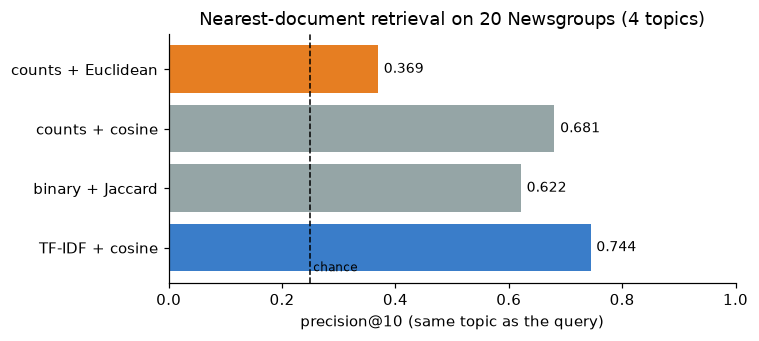

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(p10)
ax.barh(names[::-1], [p10[n] for n in names][::-1], color=["#3a7dc9", "#95a5a6", "#95a5a6", "#e67e22"])
ax.axvline(0.25, ls="--", color="k", lw=1); ax.text(0.255, -0.4, "chance", fontsize=8)
for y, n in enumerate(names[::-1]):
    ax.text(p10[n] + 0.01, y, f"{p10[n]:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel("precision@10 (same topic as the query)")
ax.set_title("Nearest-document retrieval on 20 Newsgroups (4 topics)")
plt.tight_layout(); plt.savefig(DOCS / "06_retrieval_precision.png", bbox_inches="tight"); plt.show()

All four methods beat chance, but by very different margins. Euclidean distance on counts is barely better
than guessing (0.369), because it mostly matches posts of similar *length*. Switching to cosine on the same
counts jumps to 0.681. Jaccard on word sets (0.622) loses the count information, and TF-IDF + cosine is the
clear winner (0.744): down-weighting common words makes the neighbours more topical.

## 5 · A similarity heatmap
Three test posts from each topic, compared pairwise with TF-IDF cosine similarity. We pick posts with at
least 40 tokens so that each one has some content.

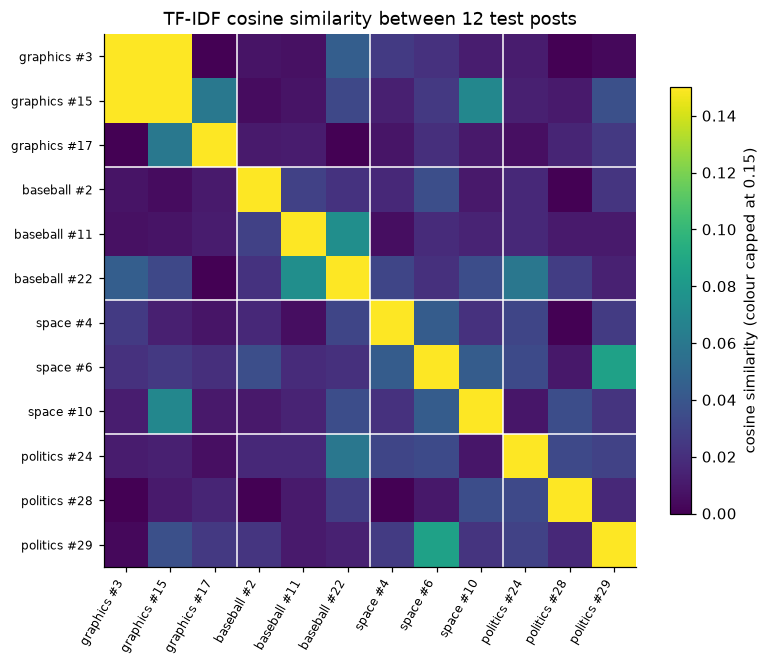

In [16]:
cats = sorted(test["category"].unique())
lengths = np.array([len(t) for t in test_tok])
pick = [i for c in cats for i in np.where((y_test == c) & (lengths >= 40))[0][:3]]
short = {"comp.graphics": "graphics", "rec.sport.baseball": "baseball", "sci.space": "space",
         "talk.politics.misc": "politics"}
labels = [f"{short[y_test[i]]} #{test.index[i]}" for i in pick]
S_heat = cosine_similarity(W_test[pick])

fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(S_heat, cmap="viridis", vmin=0, vmax=0.15)
ax.set_xticks(range(len(pick))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(pick))); ax.set_yticklabels(labels, fontsize=8)
for k in range(1, 4):
    ax.axhline(3 * k - 0.5, color="w", lw=1); ax.axvline(3 * k - 0.5, color="w", lw=1)
plt.colorbar(im, ax=ax, label="cosine similarity (colour capped at 0.15)", shrink=0.8)
ax.set_title("TF-IDF cosine similarity between 12 test posts")
plt.tight_layout(); plt.savefig(DOCS / "06_similarity_heatmap.png", bbox_inches="tight"); plt.show()

In [17]:
off = ~np.eye(len(pick), dtype=bool)
block = np.equal.outer(y_test[pick], y_test[pick])
print(f"mean cosine, same topic     : {S_heat[block & off].mean():.3f}")
print(f"mean cosine, different topic: {S_heat[~block].mean():.3f}")

mean cosine, same topic     : 0.051
mean cosine, different topic: 0.020


The diagonal is saturated (every post has cosine 1 with itself). Off the diagonal, pairs inside the white
3×3 topic blocks are on average about 2.5 times more similar than pairs from different topics — but the
picture is noisy. The two most similar posts, graphics #3 and #15 (cosine 0.234), share colour-related
vocabulary; and a few cross-topic pairs, such as space #6 and politics #29, are more similar (0.086) than the
average same-topic pair. Single pairs are unreliable; averages over many pairs are not.

### Average similarity between topics
Averaging the cosine similarity over **all** pairs of test posts gives a topic-by-topic picture.

In [18]:
S_all = cosine_similarity(W_test)
np.fill_diagonal(S_all, np.nan)
avg = pd.DataFrame([[np.nanmean(S_all[np.ix_(y_test == a, y_test == b)]) for b in cats] for a in cats],
                   index=cats, columns=cats)
avg.round(4)

,comp.graphics,rec.sport.baseball,sci.space,talk.politics.misc
comp.graphics,0.0343,0.0131,0.0157,0.0146
rec.sport.baseball,0.0131,0.0328,0.0142,0.0167
sci.space,0.0157,0.0142,0.0245,0.0171
talk.politics.misc,0.0146,0.0167,0.0171,0.0322


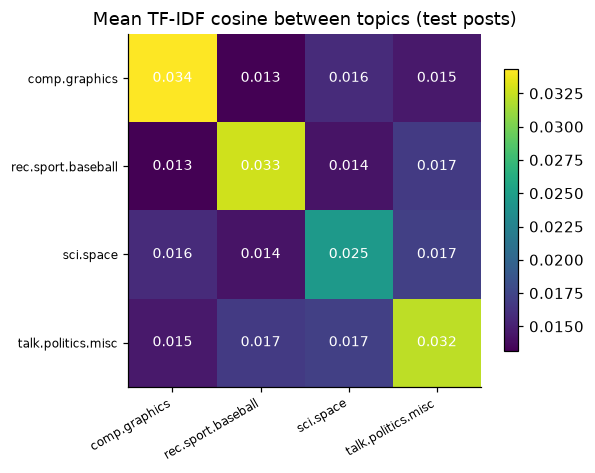

In [19]:
fig, ax = plt.subplots(figsize=(5.6, 4.4))
im = ax.imshow(avg.values, cmap="viridis")
ax.set_xticks(range(4)); ax.set_xticklabels(cats, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(4)); ax.set_yticklabels(cats, fontsize=8)
for a in range(4):
    for b in range(4):
        ax.text(b, a, f"{avg.values[a, b]:.3f}", ha="center", va="center", color="w", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Mean TF-IDF cosine between topics (test posts)")
plt.tight_layout(); plt.savefig(DOCS / "06_topic_similarity.png", bbox_inches="tight"); plt.show()

Every diagonal value (posts of the same topic) is higher than every off-diagonal value, but all the
numbers are small: two random posts share few distinctive words, even when they discuss the same topic.
Retrieval works because we only need the *ranking* to be right — the nearest neighbours — not the absolute
values.

## 6 · The limit of word-overlap similarity
Cosine over BoW or TF-IDF vectors only sees **shared words**. Two sentences that mean the same thing with
different words get a similarity of 0.

In [20]:
pair = ["the car needs new tires", "my automobile requires fresh tyres"]
v = TfidfVectorizer().fit_transform(pair)
print(f"cosine = {cosine_similarity(v)[0, 1]:.3f}")

cosine = 0.000


Fixing this needs representations in which *car* is close to *automobile*: latent semantic analysis
(notebook 07) and word embeddings (notebooks 08–09).

## 7 · Exercises

**Exercise 1.** Compute the Jaccard similarity between the **preprocessed** token sets of test post `q` and
its best TF-IDF match `best`. Is it high or low compared with the cosine similarity? Why?

In [21]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Jaccard weighs every word equally, including common ones; TF-IDF cosine focuses on the shared *distinctive* words, so the two numbers measure different things.

```python
A, B = set(test_tok[q]), set(train_tok[best])
print(f"Jaccard = {len(A & B) / len(A | B):.3f}  ({len(A & B)} shared of {len(A | B)} distinct lemmas)")
print(f"TF-IDF cosine = {sims[best]:.3f}")
```
</details>

In [22]:
A, B = set(test_tok[q]), set(train_tok[best])
print(f"Jaccard = {len(A & B) / len(A | B):.3f}  ({len(A & B)} shared of {len(A | B)} distinct lemmas)")
print(f"TF-IDF cosine = {sims[best]:.3f}")

Jaccard = 0.208  (36 shared of 173 distinct lemmas)
TF-IDF cosine = 0.400


**Exercise 2.** Near-duplicate detection: find all pairs of **training** posts with TF-IDF cosine
similarity above 0.9. How many are there, and are they from the same topic?

In [23]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Very high similarities usually come from duplicates, cross-posts or a reply that quotes most of the original post.

```python
S_tr = (W_train @ W_train.T).toarray()
np.fill_diagonal(S_tr, 0)
i_idx, j_idx = np.where(np.triu(S_tr) > 0.9)
print(f"{len(i_idx)} pairs with cosine > 0.9")
print("same topic in every pair:", all(y_train[i] == y_train[j] for i, j in zip(i_idx, j_idx)))
```
</details>

In [24]:
S_tr = (W_train @ W_train.T).toarray()
np.fill_diagonal(S_tr, 0)
i_idx, j_idx = np.where(np.triu(S_tr) > 0.9)
print(f"{len(i_idx)} pairs with cosine > 0.9")
print("same topic in every pair:", all(y_train[i] == y_train[j] for i, j in zip(i_idx, j_idx)))

23 pairs with cosine > 0.9
same topic in every pair: True


**Exercise 3.** Build a TF-IDF index of the **SMS Spam Collection** (`TfidfVectorizer(min_df=2)`) and
compute precision@10 for leave-one-out retrieval: for each message, look at its 10 most similar *other*
messages and measure how often they share its label. Report the result separately for spam and for ham
queries.

In [25]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Ham is the majority class, so ham queries find ham neighbours easily; spam messages are formulaic, so they also find each other well.

```python
sms = nlp_course.load_sms()
Ws = TfidfVectorizer(min_df=2).fit_transform(sms["text"])
Ss = (Ws @ Ws.T).toarray()
np.fill_diagonal(Ss, -1)                       # exclude the message itself
nn = np.argsort(-Ss, axis=1)[:, :10]
labels_sms = sms["label"].to_numpy()
hit = (labels_sms[nn] == labels_sms[:, None]).mean(axis=1)
for lab in ["spam", "ham"]:
    print(f"{lab:>4} queries: precision@10 = {hit[labels_sms == lab].mean():.3f}")
```
</details>

In [26]:
sms = nlp_course.load_sms()
Ws = TfidfVectorizer(min_df=2).fit_transform(sms["text"])
Ss = (Ws @ Ws.T).toarray()
np.fill_diagonal(Ss, -1)                       # exclude the message itself
nn = np.argsort(-Ss, axis=1)[:, :10]
labels_sms = sms["label"].to_numpy()
hit = (labels_sms[nn] == labels_sms[:, None]).mean(axis=1)
for lab in ["spam", "ham"]:
    print(f"{lab:>4} queries: precision@10 = {hit[labels_sms == lab].mean():.3f}")

spam queries: precision@10 = 0.782
 ham queries: precision@10 = 0.987


## Summary
- **Euclidean distance** on counts is dominated by document length; **Jaccard** compares word sets and
  ignores counts; **cosine similarity** compares directions and is the standard for text.
- With L2-normalised TF-IDF rows, cosine similarity is a plain dot product: `W @ W.T`.
- Nearest-document search and a small search engine take a few lines: transform the query, rank by cosine.
- On the newsgroups, TF-IDF + cosine retrieves same-topic posts best, and counts + Euclidean worst.
- Word-overlap similarity cannot match synonyms — the motivation for LSA and embeddings.

**Next:** [07 · Dimensionality reduction and topics — LSA and LDA](07_topic_models_lsa_lda.ipynb).